# Baseline model: Linear Regression

Predict `ClosePrice` for single-family homes from Dataset A (`02b_preprocessing_dataset_a.ipynb`) and score it with R² on the test month, **2026-04**.

Two things are picked here, both without looking at the test month:

- **The training window X.** Train on the X months right before an evaluation month. X is tuned on a rolling backtest over the 6 months before the test month (2025-10 to 2026-03).
- **The two linear-regression experiments from the procedures doc:** log target (`log1p(ClosePrice)`, with predictions converted back to dollars before scoring) and log `LivingArea` / `LotSizeSquareFeet`.

Every metric is on the dollar scale. Besides R², MAE and MAPE are reported because they're easier to read for a price model.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

from idx_exchange_data_science import dataset_a as da
from idx_exchange_data_science.modeling import backtest, best_windows, build_model, fitted_pipeline, score_on_test
from idx_exchange_data_science.splits import validation_months

pd.set_option("display.float_format", "{:,.4f}".format)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

TEST_MONTH = "2026-04"
WINDOWS = [1, 2, 3, 6, 9, 12, 18]
EVAL_MONTHS = validation_months(TEST_MONTH, n_months=6)
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

df = da.load_clean("../data/processed/CRMLSSoldDatasetA.csv")
df.shape

(309019, 20)

## 1. Model variants
Every variant has the same pipeline: `DatasetAPreprocessor` → `StandardScaler` → `LinearRegression`. Scaling doesn't change OLS predictions. It only puts the coefficients on a comparable scale.

In [2]:
models = {
    "LR": build_model(LinearRegression(), scale=True),
    "LR + log features": build_model(LinearRegression(), scale=True, log_features=True),
    "LR + log target": build_model(LinearRegression(), scale=True, log_target=True),
    "LR + log target + log features": build_model(LinearRegression(), scale=True, log_target=True, log_features=True),
}

## 2. Choosing the training window X
Each variant is fit on the X months before each validation month and scored on that month. That gives 7 windows × 6 months. The largest window that fits before 2025-10 is 21 months, so 18 is the longest one tried.

In [3]:
results = backtest(models, df, EVAL_MONTHS, WINDOWS)
mean_r2 = results.pivot_table(index="X", columns="model", values="r2", aggfunc="mean")[list(models)]
mean_r2

model,LR,LR + log features,LR + log target,LR + log target + log features
X,,,,
1,0.7604,0.7336,0.4565,0.7771
2,0.7704,0.7449,0.5075,0.7845
3,0.7778,0.7525,0.5137,0.7906
6,0.7834,0.7583,0.5252,0.7917
9,0.7863,0.7614,0.5320,0.7968
12,0.7874,0.7627,0.5476,0.7996
18,0.7894,0.7652,0.5635,0.8007


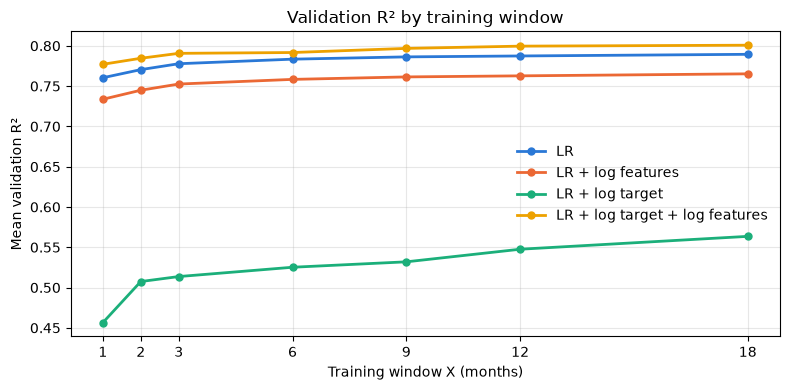

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for color, name in zip(COLORS, models):
    ax.plot(mean_r2.index, mean_r2[name], marker="o", markersize=5, linewidth=2, color=color, label=name)
ax.set(xlabel="Training window X (months)", ylabel="Mean validation R²", title="Validation R² by training window",
       xticks=WINDOWS)
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()

Month-to-month spread matters too. If one X only wins by a fraction of the spread, it isn't really better.

In [5]:
results.groupby(["model", "X"])["r2"].agg(["mean", "std", "min"]).unstack("model").swaplevel(axis=1)[list(models)]

model     LR               LR + log features               LR + log target  \
        mean    std    min              mean    std    min            mean   
X                                                                            
1     0.7604 0.0135 0.7437            0.7336 0.0193 0.7117          0.4565   
2     0.7704 0.0117 0.7589            0.7449 0.0164 0.7228          0.5075   
3     0.7778 0.0129 0.7663            0.7525 0.0172 0.7325          0.5137   
6     0.7834 0.0116 0.7700            0.7583 0.0158 0.7359          0.5252   
9     0.7863 0.0104 0.7759            0.7614 0.0142 0.7433          0.5320   
12    0.7874 0.0101 0.7776            0.7627 0.0141 0.7455          0.5476   
18    0.7894 0.0090 0.7802            0.7652 0.0121 0.7543          0.5635   

model                LR + log target + log features                
         std     min                           mean    std    min  
X                                                                  
1     0.3505 -0.2224                         0.7771 0.0121 0.7617  
2     0.2343  0.0880                         0.7845 0.0144 0.7674  
3     0.2616  0.0239                         0.7906 0.0138 0.7738  
6     0.2233  0.1395                         0.7917 0.0226 0.7510  
9     0.2182  0.1532                         0.7968 0.0175 0.7666  
12    0.2338  0.1463                         0.7996 0.0153 0.7733  
18    0.2142  0.2018                         0.8007 0.0148 0.7771

In [6]:
best_x = best_windows(results)
best_x

{'LR': 18,
 'LR + log features': 18,
 'LR + log target': 18,
 'LR + log target + log features': 18}

**Observations**
- **Longer windows help every variant.** Validation R² is still creeping up at 18 months, the longest window that fits before the validation months, so X = 18 is chosen for all four. Past 6 months the gains are small: +0.006 for plain LR between 6 and 18, which is less than its month-to-month standard deviation (about 0.01). A shorter window would cost little.
- **A log target on its own is unstable.** It has the worst mean and swings wildly from month to month, and one month even has a negative R². Without logging the features, a linear term in log price turns extreme values (lot size has no upper limit in Dataset A) into multiplicative effects, and converting back to dollars blows those predictions up.
- **Logging both the target and the features** gives the best and the most stable validation scores, so that variant is the baseline.

## 3. Test month
Each variant is refit on its chosen X months before 2026-04 and scored once on 2026-04. The baseline is the variant with the best **validation** R², not the best test R².

In [7]:
validation_r2 = {name: mean_r2.loc[x, name] for name, x in best_x.items()}
baseline_name = max(validation_r2, key=validation_r2.get)

test_results, fitted = score_on_test(models, df, TEST_MONTH, best_x)
test_results = test_results.assign(validation_r2=test_results["model"].map(validation_r2),
                                   baseline=test_results["model"] == baseline_name)
test_results

,model,X,n_train,n_test,train_r2,test_r2,test_mae,test_mape,validation_r2,baseline
0,LR,18,189534,12309,0.7989,0.8001,"265,251.8618",0.2484,0.7894,False
1,LR + log features,18,189534,12309,0.7770,0.7791,"281,638.6504",0.2696,0.7652,False
2,LR + log target,18,189534,12309,0.6762,0.7182,"221,990.0540",0.1590,0.5635,False
3,LR + log target + log features,18,189534,12309,0.8162,0.8102,"216,765.9942",0.1586,0.8007,True


**Observations**
- **Baseline test R² is 0.810** (MAE about \$217K, MAPE 15.9%). Test R² is close to validation R² (0.801), so choosing X and the variant on validation didn't overfit.
- Next to plain LR, the log variant gains only 0.01 R² but cuts MAPE from 24.8% to 15.9%. R² on dollars is driven mostly by the expensive homes, while MAPE weights every home equally.

## 4. What the baseline learned
Standardized coefficients: the change in the prediction (in log dollars if the target is logged) for a one-standard-deviation change in the feature.

In [8]:
pipeline = fitted_pipeline(fitted[baseline_name])
coefficients = pd.Series(pipeline[-1].coef_, index=pipeline[-1].feature_names_in_)
coefficients.sort_values(key=abs, ascending=False).to_frame("coefficient")

,coefficient
PostalCode_te,0.3277
LivingArea,0.1712
Longitude,-0.1007
City_te,0.0902
Latitude,-0.0893
BathroomsTotalInteger,0.0760
CountyOrParish_te,0.0435
PropertyAge,0.0389
LotSizeSquareFeet,0.0292
PoolPrivateYN,0.0209


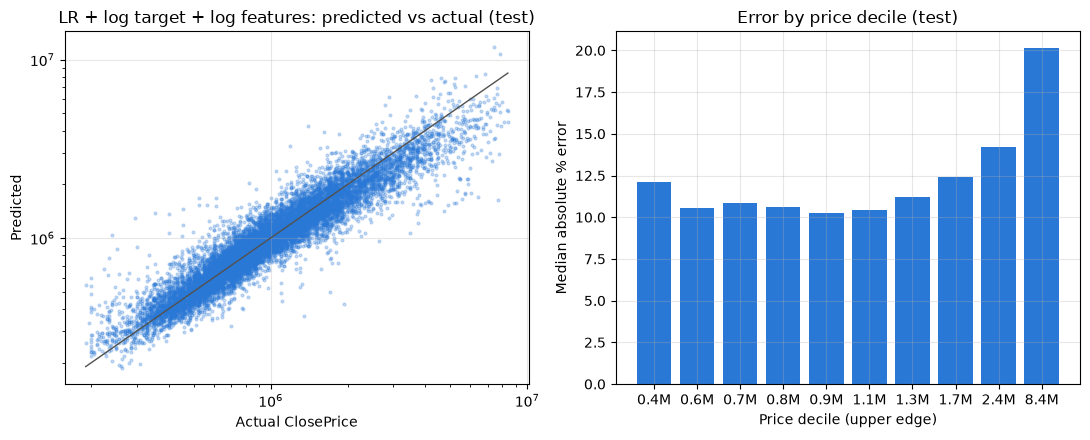

In [9]:
_, test = da.split(df, TEST_MONTH, best_x[baseline_name])
predicted = fitted[baseline_name].predict(test[da.FEATURES])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(test[da.TARGET], predicted, s=4, alpha=0.25, color=COLORS[0])
limits = [test[da.TARGET].min(), test[da.TARGET].max()]
axes[0].plot(limits, limits, color="#52514e", linewidth=1)
axes[0].set(xscale="log", yscale="log", xlabel="Actual ClosePrice", ylabel="Predicted",
            title=f"{baseline_name}: predicted vs actual (test)")

price_band = pd.qcut(test[da.TARGET], 10)
abs_pct_error = (np.abs(predicted - test[da.TARGET]) / test[da.TARGET]).groupby(price_band, observed=True).median()
axes[1].bar(range(10), abs_pct_error.values * 100, color=COLORS[0], width=0.8)
axes[1].set(xticks=range(10), xticklabels=[f"{b.right / 1e6:.1f}M" for b in abs_pct_error.index],
            xlabel="Price decile (upper edge)", ylabel="Median absolute % error", title="Error by price decile (test)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()

**Observations**
- **Location dominates.** The ZIP target encoding has the largest coefficient, followed by living area, then coordinates and the city encoding. Bedrooms gets a slightly negative coefficient once living area and bathrooms are in the model, because those features overlap.
- **Errors grow at the extremes.** The median error is about 10–12% through the middle of the market and rises to about 20% in the top decile. Predictions are pulled toward the middle: cheap homes are overpredicted and the most expensive ones underpredicted. A single linear surface can't bend for the luxury market. That is the main gap the tree models should close.

## 5. Record results

In [10]:
test_results.to_csv(RESULTS_DIR / "baseline_results.csv", index=False)
results.to_csv(RESULTS_DIR / "baseline_backtest.csv", index=False)
print(f"Baseline: {baseline_name}, X = {best_x[baseline_name]} months, "
      f"test R² = {test_results.loc[test_results['baseline'], 'test_r2'].item():.4f}")

Baseline: LR + log target + log features, X = 18 months, test R² = 0.8102
